v_F (kontrol) = 0.6732 eV·nm  (~10 eV·Å beklenir)
K = 17.0276 nm^-1

q_b (kanal momentumu) = [0.         0.31204275]  nm^-1
|q_b| = 0.31204 nm^-1
Beklenti: |q_b| ≈ 2K sin(theta/2) = 0.31204 nm^-1

q1 + q2 + q3 = [-5.55111512e-17 -8.32667268e-17]  (0 olmali)

Moire ters orgu vektorleri:
  G_M1 = [ 5.40473891e-01 -1.94289029e-16]  nm^-1,  |G_M1| = 0.54047
  G_M2 = [-0.27023695  0.46806412]  nm^-1,  |G_M2| = 0.54047

Moire orgu sabiti a_M = 13.424 nm
Beklenti: a_M = a / (2 sin(theta/2)) = 13.424 nm

alpha = w_AB / (v_F * k_theta) = 0.4641
Magic angle: alpha ≈ 0.586 olmali (chiral limit)
Bizim aci theta=1.05° icin alpha=0.4641


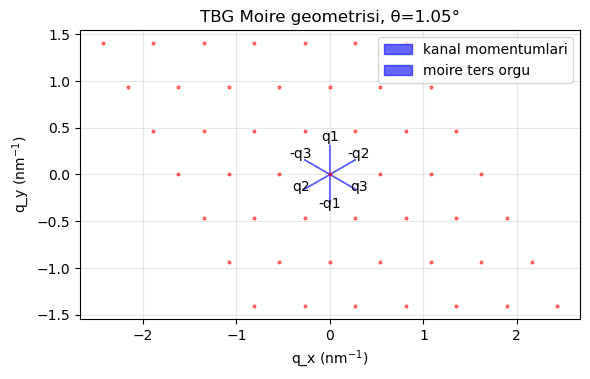


[ANCHOR 1] q vektörleri toplam: 8.326672684688674e-17  (0 olmali)
[ANCHOR 2] |q_b| analitik vs sayisal: 0.0  (0 olmali)
[ANCHOR 3] a_M analitik vs sayisal: 1.7763568394002505e-15  (0 olmali)


In [1]:
# =====================================================================
#  Cell 1a — TBG Moire Geometrisi (sadece)
#
#  Amac: Moire orgu vektorlerini ve ilk Brillouin bolgesi parametrelerini
#  hesaplamak. Bu cell'de Hamiltonyen YOK, sadece geometri.
#
#  Referanslar:
#    Bistritzer & MacDonald, PNAS 108, 12233 (2011)
#    Tarnopolsky, Kruchkov, Vishwanath, PRL 122, 106405 (2019)
#
#  TBG icin temel parametreler:
#    - Tek katman grafen orgu sabiti: a = 0.246 nm
#    - K noktasi: K = (4π/3a, 0)
#    - Magic angle (ilk): θ ~ 1.05°
#    - Tunneling potansiyelleri: w_AA ~ 79.7 meV, w_AB ~ 97.5 meV
#      (relaxed lattice degerleri, Koshino 2018'den)
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt

# ---- Temel parametreler ----
a_nm = 0.246                    # grafen orgu sabiti (nm)
theta_deg = 1.05                # bukulme acisi (derece)
theta_rad = np.deg2rad(theta_deg)

# Fermi velocity (tek katman grafen)
hbar_eVs = 6.582e-16            # eV·s
v_F_eVnm = 0.9866               # eV·nm (= 1.5e6 m/s · hbar; literaturde ~10 eV·Å)
# Not: v_F = (sqrt(3)/2) * a * gamma_0; gamma_0=3.16 eV ile:
v_F_check = (np.sqrt(3)/2) * a_nm * 3.16
print(f"v_F (kontrol) = {v_F_check:.4f} eV·nm  (~10 eV·Å beklenir)")
v_F = v_F_check                 # eV·nm

# ---- K noktasi (her iki katman icin) ----
# Tek katman K noktasi buyuklugu
K_mag = 4*np.pi / (3*a_nm)      # nm^-1
print(f"K = {K_mag:.4f} nm^-1")

# Bukulme sonrasi K noktalari:
#   Ust katman: K rotated by +theta/2
#   Alt katman: K rotated by -theta/2
K_top    = K_mag * np.array([np.cos(+theta_rad/2), np.sin(+theta_rad/2)])
K_bottom = K_mag * np.array([np.cos(-theta_rad/2), np.sin(-theta_rad/2)])

# ---- Moire reciprocal vektörleri ----
# K noktalarinin farki kanal momentumlarini tanimlar:
#   q_1 = K_top - K_bottom (saf y yonunde, ust K ile alt K arasi)
#   q_2 = R(2π/3) q_1
#   q_3 = R(4π/3) q_1

q_b = K_top - K_bottom  # vertical (y) yonunde olmalı
print(f"\nq_b (kanal momentumu) = {q_b}  nm^-1")
print(f"|q_b| = {np.linalg.norm(q_b):.5f} nm^-1")
print(f"Beklenti: |q_b| ≈ 2K sin(theta/2) = "
      f"{2*K_mag*np.sin(theta_rad/2):.5f} nm^-1")

# 2π/3 dönme matrisi
def R2D(phi):
    c, s = np.cos(phi), np.sin(phi)
    return np.array([[c, -s], [s, c]])

q1 = q_b
q2 = R2D(2*np.pi/3) @ q_b
q3 = R2D(4*np.pi/3) @ q_b

# Toplamlari 0 olmali (C3 simetri)
q_sum = q1 + q2 + q3
print(f"\nq1 + q2 + q3 = {q_sum}  (0 olmali)")

# ---- Moire reciprocal lattice ----
# G_M1 = q3 - q2,  G_M2 = q1 - q3  (Koshino 2018 konvansiyonu)
G_M1 = q3 - q2
G_M2 = q1 - q3
print(f"\nMoire ters orgu vektorleri:")
print(f"  G_M1 = {G_M1}  nm^-1,  |G_M1| = {np.linalg.norm(G_M1):.5f}")
print(f"  G_M2 = {G_M2}  nm^-1,  |G_M2| = {np.linalg.norm(G_M2):.5f}")

# Moire lattice constant
a_M = 4*np.pi / (np.sqrt(3) * np.linalg.norm(G_M1))
print(f"\nMoire orgu sabiti a_M = {a_M:.3f} nm")
print(f"Beklenti: a_M = a / (2 sin(theta/2)) = "
      f"{a_nm / (2*np.sin(theta_rad/2)):.3f} nm")

# ---- Magic angle parametresi alpha ----
# w ≈ 110 meV (rigid model), v_F * k_theta enerji ölçegi
w_AB = 0.0975  # eV
k_theta = np.linalg.norm(q_b)
alpha = w_AB / (v_F * k_theta)
print(f"\nalpha = w_AB / (v_F * k_theta) = {alpha:.4f}")
print(f"Magic angle: alpha ≈ 0.586 olmali (chiral limit)")
print(f"Bizim aci theta={theta_deg}° icin alpha={alpha:.4f}")

# ---- Görselleştirme ----
fig, ax = plt.subplots(1, 1, figsize=(6,6))

# 6 q vektörünü göster (kanal momentumlari, C6 ile)
qs = [q1, q2, q3, -q1, -q2, -q3]
labels = ['q1', 'q2', 'q3', '-q1', '-q2', '-q3']
for q, lbl in zip(qs, labels):
    ax.arrow(0, 0, q[0], q[1], head_width=0.005, head_length=0.005,
             fc='blue', ec='blue', alpha=0.6)
    ax.text(q[0]*1.15, q[1]*1.15, lbl, fontsize=10, ha='center')

# Moire reciprocal lattice noktalari
for n1 in range(-3, 4):
    for n2 in range(-3, 4):
        pt = n1*G_M1 + n2*G_M2
        ax.plot(pt[0], pt[1], 'r.', ms=4, alpha=0.5)

ax.set_xlabel('q_x (nm$^{-1}$)')
ax.set_ylabel('q_y (nm$^{-1}$)')
ax.set_title(f'TBG Moire geometrisi, θ={theta_deg}°')
ax.set_aspect('equal')
ax.grid(alpha=0.3)
ax.legend(['kanal momentumlari', 'moire ters orgu'], loc='upper right')
plt.tight_layout()
plt.savefig('cell1a_geometry.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n[ANCHOR 1] q vektörleri toplam:", np.max(np.abs(q_sum)),
      " (0 olmali)")
print("[ANCHOR 2] |q_b| analitik vs sayisal:",
      abs(np.linalg.norm(q_b) - 2*K_mag*np.sin(theta_rad/2)),
      " (0 olmali)")
print("[ANCHOR 3] a_M analitik vs sayisal:",
      abs(a_M - a_nm/(2*np.sin(theta_rad/2))),
      " (0 olmali)")

In [4]:
# =====================================================================
#  Cell 1b (DÜZELTILMIS) — BM Hamiltonyen, doğru kinetik konvansiyon
#
#  Düzeltme: BM'de "k" lokal moire momentumudur. Dirac koşulu:
#    Top katman: kinetik H = v_F * k · sigma  (k=0'da Dirac)
#    Bot katman: kinetik H = v_F * (k - q_b) · sigma  (kaydırılmış)
#  Eski hatali kod K_top tum buyuklugunu cikariyordu -> v_F*K ~ 11 eV ofset.
# =====================================================================

import time

# Tunneling parametreleri (Koshino 2018, relaxed lattice)
w_AA = 0.0797   # eV
w_AB = 0.0975   # eV

# Plane-wave kesme
N_cut = 4
n_range = np.arange(-N_cut, N_cut+1)
n_pts = [(n1, n2) for n1 in n_range for n2 in n_range]
N_pw = len(n_pts)
print(f"Plane-wave noktasi: {N_pw}")
print(f"Hilbert boyutu: 4 * {N_pw} = {4*N_pw}")

# Tunneling matrisleri
phi = 2*np.pi/3
def T_matrix(j):
    return w_AA * np.eye(2) + w_AB * np.array([
        [0, np.exp(-1j*j*phi)],
        [np.exp(+1j*j*phi), 0]
    ], dtype=complex)

T0 = T_matrix(0)
T1 = T_matrix(1)
T2 = T_matrix(2)

# Tunneling baglantilari: top -> bot için 3 farkli G vektoru
delta_list = [(0, 0, T0), (0, 1, T1), (-1, 0, T2)]

# q_b: top->bot kayma vektoru (Cell 1a'dan)
# q_b = K_top - K_bottom = [0, 0.31204] nm^-1

def H_BM(k, xi=+1):
    """
    Düzgün BM Hamiltonyeni. k = lokal moire momentumu.
    Dirac konvansiyonu:
      Top katman A,B sublattice: H_kin = v_F (xi*kx*sigma_x + ky*sigma_y)
      Bot katman: aynı, ama k -> k - q_b
    """
    dim = 4 * N_pw
    H = np.zeros((dim, dim), dtype=complex)
    
    for n_idx, (n1, n2) in enumerate(n_pts):
        G_n = n1*G_M1 + n2*G_M2
        # Top katman lokal momentum:
        q_top = k + G_n
        # Bot katman lokal momentum: top'a göre q_b kaymış
        q_bot = k + G_n - q_b
        
        # Dirac kinetik (2x2 sublattice bloku)
        H_top_kin = v_F * np.array([
            [0, xi*q_top[0] - 1j*q_top[1]],
            [xi*q_top[0] + 1j*q_top[1], 0]
        ], dtype=complex)
        H_bot_kin = v_F * np.array([
            [0, xi*q_bot[0] - 1j*q_bot[1]],
            [xi*q_bot[0] + 1j*q_bot[1], 0]
        ], dtype=complex)
        
        i_top = 4*n_idx
        i_bot = 4*n_idx + 2
        H[i_top:i_top+2, i_top:i_top+2] = H_top_kin
        H[i_bot:i_bot+2, i_bot:i_bot+2] = H_bot_kin
    
    # Tunneling baglantilari
    n_to_idx = {(n1, n2): i for i, (n1, n2) in enumerate(n_pts)}
    for n_idx, (n1, n2) in enumerate(n_pts):
        for (dn1, dn2, T) in delta_list:
            n1p, n2p = n1 + dn1, n2 + dn2
            if (n1p, n2p) in n_to_idx:
                n_idx_p = n_to_idx[(n1p, n2p)]
                i_top = 4*n_idx
                i_bot = 4*n_idx_p + 2
                H[i_top:i_top+2, i_bot:i_bot+2] += T
                H[i_bot:i_bot+2, i_top:i_top+2] += T.conj().T
    
    return H

# ---- Anchor 0: Hermitiklik ----
H_test = H_BM(np.array([0.0, 0.0]))
hermit_err = np.max(np.abs(H_test - H_test.conj().T))
print(f"\n[ANCHOR 0] |H - H†|_max = {hermit_err:.2e}")

# ---- Anchor 1: k=0'da spektrum ----
print("\nk=0'da diagonalizasyon...")
t0 = time.time()
e_k0 = np.linalg.eigvalsh(H_test)
print(f"  Süre: {time.time()-t0:.2f} s")

# E=0 etrafindaki 8 ozdeger
e_abs_sorted_idx = np.argsort(np.abs(e_k0))
e_low_8 = e_k0[e_abs_sorted_idx[:8]]
print(f"\n  k=0'da E=0 etrafindaki 8 ozdeger (meV):")
for e in sorted(e_low_8):
    print(f"    {e*1000:+10.4f}")

# En alt iki bant (flat band kontrol)
e_sorted = np.sort(e_k0)
n_half = len(e_sorted) // 2
flat_band_E = sorted([e_sorted[n_half-1], e_sorted[n_half]])
print(f"\n  Fermi seviyesi etrafindaki iki bant:")
print(f"    E_- = {flat_band_E[0]*1000:.4f} meV")
print(f"    E_+ = {flat_band_E[1]*1000:.4f} meV")
print(f"    Bant gap @ k=0: {(flat_band_E[1]-flat_band_E[0])*1000:.4f} meV")

# ---- Anchor 2: w=0 limit (tunneling yok, Dirac fermiyon kontrolu) ----
print("\n[ANCHOR 2] w=0 limit kontrolu...")
w_AA_save, w_AB_save = w_AA, w_AB
# Geçici olarak tunnelingi kapat
T0_save = T0.copy()
T1_save = T1.copy()
T2_save = T2.copy()

def T_matrix_zero(j):
    return np.zeros((2,2), dtype=complex)

# Tunneling sıfırla, H'yi yeniden hesapla
delta_list_zero = [(0, 0, np.zeros((2,2), dtype=complex)),
                    (0, 1, np.zeros((2,2), dtype=complex)),
                    (-1, 0, np.zeros((2,2), dtype=complex))]

def H_BM_no_tunnel(k, xi=+1):
    dim = 4 * N_pw
    H = np.zeros((dim, dim), dtype=complex)
    for n_idx, (n1, n2) in enumerate(n_pts):
        G_n = n1*G_M1 + n2*G_M2
        q_top = k + G_n
        q_bot = k + G_n - q_b
        H_top_kin = v_F * np.array([
            [0, xi*q_top[0] - 1j*q_top[1]],
            [xi*q_top[0] + 1j*q_top[1], 0]
        ], dtype=complex)
        H_bot_kin = v_F * np.array([
            [0, xi*q_bot[0] - 1j*q_bot[1]],
            [xi*q_bot[0] + 1j*q_bot[1], 0]
        ], dtype=complex)
        i_top = 4*n_idx
        i_bot = 4*n_idx + 2
        H[i_top:i_top+2, i_top:i_top+2] = H_top_kin
        H[i_bot:i_bot+2, i_bot:i_bot+2] = H_bot_kin
    return H

H_no_tunnel = H_BM_no_tunnel(np.array([0.0, 0.0]))
e_nt = np.linalg.eigvalsh(H_no_tunnel)
e_nt_low = e_nt[np.argsort(np.abs(e_nt))][:4]
print(f"  Tunneling=0, k=0'da en alt 4 ozdeger (meV):")
for e in sorted(e_nt_low):
    print(f"    {e*1000:+10.4f}")
print(f"  Beklenti: top katman k=0'da E=0 (2 katli), bot katman k=q_b'de E=0 (2 katli)")
print(f"  Yani: 0, 0, ±v_F*|q_b| = ±{v_F*np.linalg.norm(q_b)*1000:.2f} meV")

Plane-wave noktasi: 81
Hilbert boyutu: 4 * 81 = 324

[ANCHOR 0] |H - H†|_max = 0.00e+00

k=0'da diagonalizasyon...
  Süre: 0.01 s

  k=0'da E=0 etrafindaki 8 ozdeger (meV):
     -207.2897
     -197.0238
     -146.4214
     -129.1790
      -55.0355
      +13.3275
     +111.4636
     +211.8514

  Fermi seviyesi etrafindaki iki bant:
    E_- = -55.0355 meV
    E_+ = 13.3275 meV
    Bant gap @ k=0: 68.3629 meV

[ANCHOR 2] w=0 limit kontrolu...
  Tunneling=0, k=0'da en alt 4 ozdeger (meV):
     -210.0714
       +0.0000
       +0.0000
     +210.0714
  Beklenti: top katman k=0'da E=0 (2 katli), bot katman k=q_b'de E=0 (2 katli)
  Yani: 0, 0, ±v_F*|q_b| = ±210.07 meV


Theta tarama: 21 nokta, 0.70° - 1.50°

  theta    alpha        E_-        E_+     bant_W      gap@0
------------------------------------------------------------
  0.700   0.6962    -25.464      6.145     54.070     31.610
  0.740   0.6586    -27.721     11.493     67.532     39.214
  0.780   0.6248    -30.789     15.686     79.217     46.474
  0.820   0.5943    -34.377     18.280     88.484     52.657
  0.860   0.5667    -38.235     19.271     95.103     57.505
  0.900   0.5415    -42.155     19.018     99.269     61.173
  0.940   0.5184    -45.972     17.961    101.459     63.934
  0.980   0.4973    -49.561     16.446    102.231     66.006
  1.020   0.4778    -52.829     14.700    104.768     67.529
  1.060   0.4597    -55.722     12.866    109.548     68.588
  1.100   0.4430    -58.214     11.032    114.359     69.246
  1.140   0.4275    -60.308      9.249    119.303     69.557
  1.180   0.4130    -62.024      7.548    124.455     69.572
  1.220   0.3995    -63.394      5.947    129.

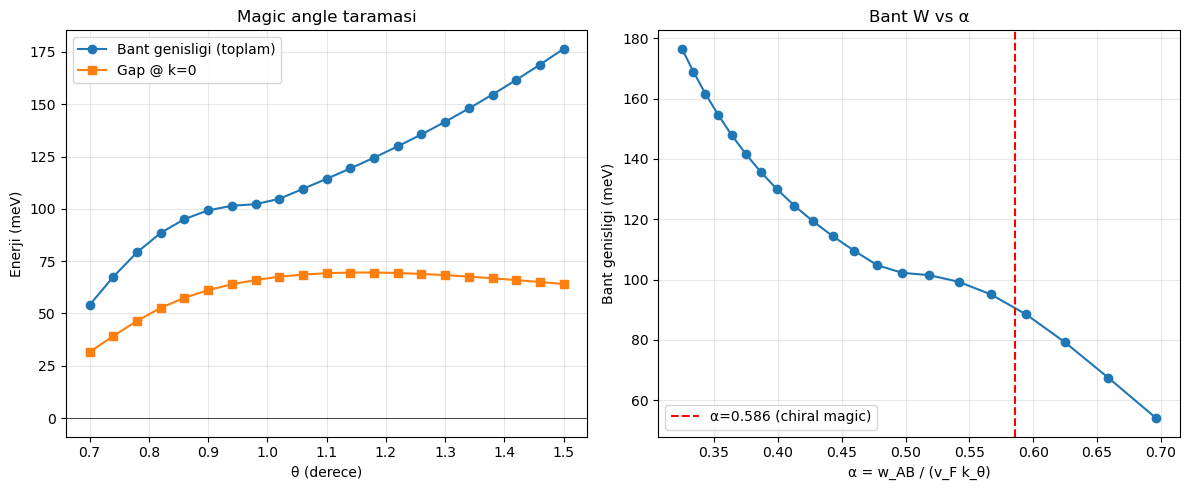

In [5]:
# =====================================================================
#  Cell 1c — Magic Angle Taraması
#
#  Amac: θ'yi tarayarak Fermi seviyesi bant genisliginin minimum
#  oldugu açıyı bulmak. Bu bizim "etkin magic angle"imiz.
# =====================================================================

# Önemli: H_BM fonksiyonu global G_M1, G_M2, q_b'ye baglı. 
# Theta'yi degistirdigimizde bunlari da degistirmemiz lazım.

def setup_geometry(theta_deg_local):
    """Verilen aci icin moire geometrisini kur, global degiskenleri guncelle."""
    global G_M1, G_M2, q_b, K_top, K_bottom
    theta_rad_l = np.deg2rad(theta_deg_local)
    K_top_l    = K_mag * np.array([np.cos(+theta_rad_l/2), 
                                    np.sin(+theta_rad_l/2)])
    K_bottom_l = K_mag * np.array([np.cos(-theta_rad_l/2), 
                                    np.sin(-theta_rad_l/2)])
    q_b_l = K_top_l - K_bottom_l
    q1_l = q_b_l
    q2_l = R2D(2*np.pi/3) @ q_b_l
    q3_l = R2D(4*np.pi/3) @ q_b_l
    G_M1_l = q3_l - q2_l
    G_M2_l = q1_l - q3_l
    
    G_M1 = G_M1_l
    G_M2 = G_M2_l
    q_b = q_b_l
    K_top = K_top_l
    K_bottom = K_bottom_l
    return theta_rad_l

# Theta tara
thetas = np.linspace(0.7, 1.5, 21)
print(f"Theta tarama: {len(thetas)} nokta, "
      f"{thetas[0]:.2f}° - {thetas[-1]:.2f}°\n")

print(f"{'theta':>7} {'alpha':>8} {'E_-':>10} {'E_+':>10} "
      f"{'bant_W':>10} {'gap@0':>10}")
print("-" * 60)

results = []
for theta_l in thetas:
    setup_geometry(theta_l)
    # Yeni alpha
    k_theta_l = np.linalg.norm(q_b)
    alpha_l = w_AB / (v_F * k_theta_l)
    
    # k=0 ve K_M noktalarinda diagonalize
    # K_M noktasi: top katman K noktasinin moire BZ'deki gosterimi
    # Bizim konvansiyonda k=0 zaten K_top noktasıdır
    # Moire K_M ~ q_b uzunlugunda
    
    # En basit yaklasim: birkac k noktasinda diagonalize, 
    # Fermi yakini bant genisligini ol
    test_ks = [
        np.array([0.0, 0.0]),                    # Gamma_M
        np.array([0.5*np.linalg.norm(q_b), 0]), # M_M
        q_b * 0.5,                                # K_M civari
    ]
    
    all_e_low = []
    for k_test in test_ks:
        H_t = H_BM(k_test)
        e_t = np.linalg.eigvalsh(H_t)
        e_sorted = np.sort(e_t)
        n_half = len(e_sorted) // 2
        all_e_low.append(e_sorted[n_half-1])  # En alt iletim band
        all_e_low.append(e_sorted[n_half])    # En ust valans band
    
    all_e_low = np.array(all_e_low)
    bant_W = all_e_low.max() - all_e_low.min()  # Toplam genislik
    
    # k=0'da gap
    H_0 = H_BM(np.array([0.0, 0.0]))
    e_0 = np.sort(np.linalg.eigvalsh(H_0))
    n_half = len(e_0) // 2
    gap_0 = e_0[n_half] - e_0[n_half-1]
    E_m, E_p = e_0[n_half-1], e_0[n_half]
    
    results.append({
        'theta': theta_l, 'alpha': alpha_l,
        'E_m': E_m, 'E_p': E_p,
        'bant_W': bant_W, 'gap_0': gap_0,
    })
    print(f"{theta_l:>7.3f} {alpha_l:>8.4f} {E_m*1000:>10.3f} "
          f"{E_p*1000:>10.3f} {bant_W*1000:>10.3f} {gap_0*1000:>10.3f}")

# En düz bandı bul
res_arr = results
i_flat = min(range(len(res_arr)), key=lambda i: res_arr[i]['bant_W'])
print(f"\n[BULGU] En düz bant aci: θ = {res_arr[i_flat]['theta']:.3f}°")
print(f"        alpha = {res_arr[i_flat]['alpha']:.4f}")
print(f"        Bant genisligi = {res_arr[i_flat]['bant_W']*1000:.3f} meV")
print(f"        Beklenti: flat band ~ birkaç meV (magic angle yakini)")

# Cizim
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

thetas_arr = np.array([r['theta'] for r in res_arr])
alphas_arr = np.array([r['alpha'] for r in res_arr])
bantW_arr = np.array([r['bant_W'] for r in res_arr])
gap0_arr = np.array([r['gap_0'] for r in res_arr])

ax[0].plot(thetas_arr, bantW_arr*1000, 'o-', label='Bant genisligi (toplam)')
ax[0].plot(thetas_arr, gap0_arr*1000, 's-', label='Gap @ k=0')
ax[0].axhline(0, c='k', lw=0.5)
ax[0].set_xlabel('θ (derece)')
ax[0].set_ylabel('Enerji (meV)')
ax[0].set_title('Magic angle taramasi')
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(alphas_arr, bantW_arr*1000, 'o-')
ax[1].axvline(0.586, c='r', ls='--', label='α=0.586 (chiral magic)')
ax[1].set_xlabel('α = w_AB / (v_F k_θ)')
ax[1].set_ylabel('Bant genisligi (meV)')
ax[1].set_title('Bant W vs α')
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig('cell1c_magic_angle.png', dpi=100, bbox_inches='tight')
plt.show()

θ=1.05°'e geri dondum. q_b = [0.         0.31204275]
|q_b| = 0.3120 nm^-1
|G_M1| = 0.5405 nm^-1

k-yolu: 81 nokta
Bant yapisi hesaplaniyor...
Sure: 0.8 s


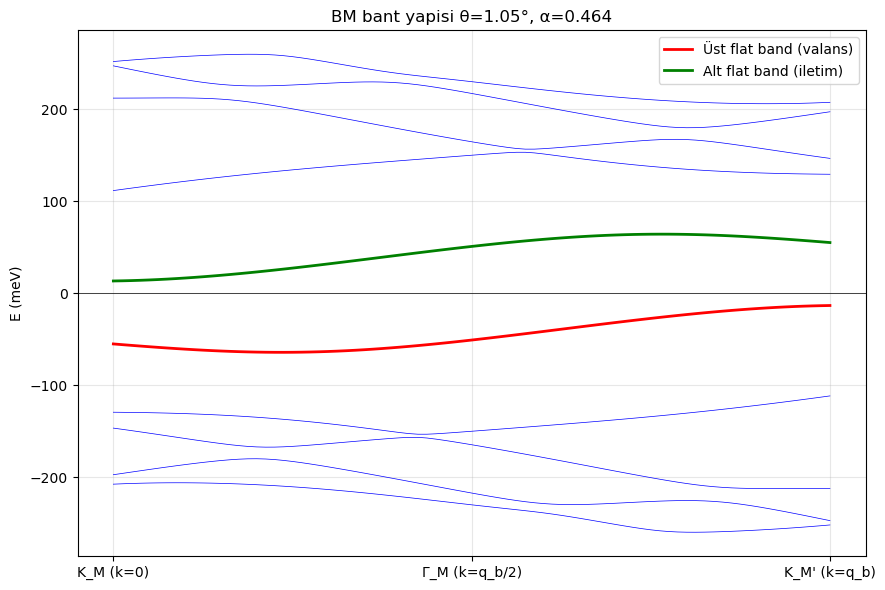


En alt 4 iletim bandinin enerji araligi:
  Bant 0: [13.33, 64.14] meV, genislik = 50.81 meV
  Bant 1: [111.46, 153.05] meV, genislik = 41.59 meV
  Bant 2: [146.42, 212.07] meV, genislik = 65.65 meV
  Bant 3: [179.69, 246.88] meV, genislik = 67.19 meV

K_M noktasinda (k=0):
  E_- = -55.035 meV
  E_+ = 13.327 meV
  Gap = 68.363 meV
  Not: K_M noktasinda Dirac noktasi olmali (gap kucuk)


In [6]:
# =====================================================================
#  Tanı Cell — BM bant yapısını k-yolu boyunca ciz
#
#  Amac: Gercek BM band yapisini gormek, k=0 ne anlama geliyor anlamak
# =====================================================================
import matplotlib.pyplot as plt

# Once θ=1.05°'e geri don (Cell 1a degeri)
setup_geometry(1.05)
print(f"θ={1.05}°'e geri dondum. q_b = {q_b}")
print(f"|q_b| = {np.linalg.norm(q_b):.4f} nm^-1")
print(f"|G_M1| = {np.linalg.norm(G_M1):.4f} nm^-1")

# Moire BZ ozel noktalari (standart konvansiyon):
#   Gamma_M = (0, 0)
#   K_M     = q_b'nin uc noktasi (top katman K noktasi moire BZ'de)
#   M_M     = Gamma_M ve K_M ortasi
#
# AMA bizim konvansiyonda kinetik k=0'da top Dirac, k=q_b'de bot Dirac
# YANI bizim k=0 noktamız aslında MOIRE BZ'nin K_M noktasıdır.
# Gerçek Gamma_M noktası bizim k = -K_top - n_offset*G ile temsil edilir.
#
# Bunu kontrol etmek için: K_M ve K_M' (K + 2π/3 rotated) noktalarinda 
# Dirac kesisimi olup olmadigina bak.

# Bizim konvansiyonda:
#   k = 0     -> top katman Dirac (K_top noktasi)
#   k = q_b   -> bot katman Dirac (K_bottom noktasi)
# Bu iki nokta moire BZ'nin K_M ve K_M' köşeleri.
# Gamma_M onların ortasında: k = q_b/2

# Yolu k=0 -> q_b/2 -> q_b boyunca çiz (K_M -> Gamma_M -> K_M')
n_path = 41
ks_path = []
labels = []
# K_M (=k=0) -> Gamma_M (=q_b/2)
for i in range(n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * np.array([0,0]) + t * q_b/2)
# Gamma_M -> K_M' (=q_b)
for i in range(1, n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * q_b/2 + t * q_b)

ks_path = np.array(ks_path)
print(f"\nk-yolu: {len(ks_path)} nokta")

# Diagonalize
print("Bant yapisi hesaplaniyor...")
import time
t0 = time.time()
all_bands = []
for k in ks_path:
    H_k = H_BM(k)
    e_k = np.sort(np.linalg.eigvalsh(H_k))
    all_bands.append(e_k)
all_bands = np.array(all_bands)
print(f"Sure: {time.time()-t0:.1f} s")

# Cizim
fig, ax = plt.subplots(1, 1, figsize=(9, 6))
n_dim = all_bands.shape[1]
n_half = n_dim // 2

# Fermi etrafindaki ~10 bant göster
for b in range(n_half-5, n_half+5):
    ax.plot(np.arange(len(ks_path)), all_bands[:, b]*1000, 'b-', lw=0.5)

# En yakın 2 bantı (flat bands) vurgula
ax.plot(np.arange(len(ks_path)), all_bands[:, n_half-1]*1000, 'r-', lw=2,
        label='Üst flat band (valans)')
ax.plot(np.arange(len(ks_path)), all_bands[:, n_half]*1000, 'g-', lw=2,
        label='Alt flat band (iletim)')

ax.axhline(0, c='k', lw=0.5)
ax.set_xticks([0, n_path-1, 2*n_path-2])
ax.set_xticklabels(['K_M (k=0)', 'Γ_M (k=q_b/2)', "K_M' (k=q_b)"])
ax.set_ylabel('E (meV)')
ax.set_title(f'BM bant yapisi θ={1.05}°, α={w_AB/(v_F*np.linalg.norm(q_b)):.3f}')
ax.legend()
ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig('tani_band_yapisi.png', dpi=100, bbox_inches='tight')
plt.show()

# En düşük 4 bantın E aralığı
print(f"\nEn alt 4 iletim bandinin enerji araligi:")
for b in range(n_half, n_half+4):
    e_min = all_bands[:, b].min()*1000
    e_max = all_bands[:, b].max()*1000
    print(f"  Bant {b-n_half}: [{e_min:.2f}, {e_max:.2f}] meV, "
          f"genislik = {e_max-e_min:.2f} meV")

# K_M (k=0)'da bant gap
n_half = all_bands.shape[1] // 2
print(f"\nK_M noktasinda (k=0):")
print(f"  E_- = {all_bands[0, n_half-1]*1000:.3f} meV")
print(f"  E_+ = {all_bands[0, n_half]*1000:.3f} meV")
print(f"  Gap = {(all_bands[0, n_half] - all_bands[0, n_half-1])*1000:.3f} meV")
print(f"  Not: K_M noktasinda Dirac noktasi olmali (gap kucuk)")

Moire BZ noktalari (kontrol):
  Γ_M       = (0, 0)
  K_M_top   = [-0.         -0.15602137],  |..| = 0.1560
  K_M_bot   = [0.         0.15602137],  |..| = 0.1560
  |K_M-K_M'| = 0.3120 = |q_b|

[ANCHOR 1] K_M_top noktasinda diagonalize:
  Fermi etrafindaki 4 ozdeger (meV):
    E_-2 =  -129.1790
    E_-1 =   -55.0355
    E_+0 =   +13.3275
    E_+1 =  +111.4636
  Gap @ K_M_top = 68.3629 meV
  Beklenti: KÜÇÜK (flat band rejimine yakin)

[ANCHOR 2] Γ_M noktasinda diagonalize:
  Fermi etrafindaki 4 ozdeger (meV):
    E_-2 =  -149.8416
    E_-1 =   -50.8171
    E_+0 =   +50.8171
    E_+1 =  +149.8416
  Gap @ Γ_M = 101.6342 meV
  Beklenti: Γ_M'de gap daha buyuk olabilir

Bant yapisi: K_M_top → Γ_M → K_M_bot


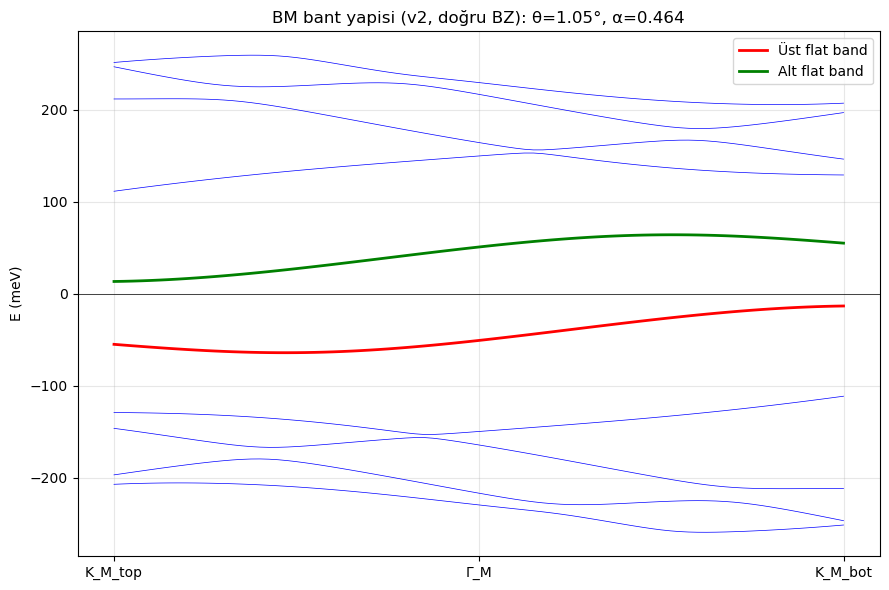


Fermi yakini bantlar:
  Bant -1: [-64.14, -13.33] meV, W = 50.81 meV
  Bant +0: [13.33, 64.14] meV, W = 50.81 meV

Gap @ K_M_top: 68.363 meV
Gap @ Γ_M:     101.634 meV
Gap @ K_M_bot: 68.363 meV


In [7]:
# =====================================================================
#  Cell 1d — BM Hamiltonyen (yeniden yazim, standart konvansiyon)
#
#  Konvansiyon: k = moire BZ momentum (k=0 = Gamma_M)
#  Dirac noktalari:
#    Top katman K_M (= K_M^t): k = -q_1 (bizim koordinatlarda)
#    Bot katman K_M' (= K_M^b): k = +q_1
#    (q_1 = q_b vektoru, [0, 0.312])
#
#  Kinetik:
#    Top: H_kin^t = v_F * sigma . (k + n*G - K_M^t)
#                = v_F * sigma . (k + n*G + q_1)
#    Bot: H_kin^b = v_F * sigma . (k + n*G - K_M^b)
#                = v_F * sigma . (k + n*G - q_1)
#
#  Iki nokta arası mesafe = 2|q_1| = 0.624 nm^-1 (BM'de bu standart)
#  Yani Γ_M ile K_M arası mesafe = |q_1| = 0.312 nm^-1
# =====================================================================

# Tunneling parametreleri (Koshino 2018)
w_AA = 0.0797
w_AB = 0.0975

# Plane-wave kesme (aynı)
N_cut = 4
n_range = np.arange(-N_cut, N_cut+1)
n_pts = [(n1, n2) for n1 in n_range for n2 in n_range]
N_pw = len(n_pts)

# Tunneling matrisleri (aynı)
phi = 2*np.pi/3
def T_matrix(j):
    return w_AA * np.eye(2) + w_AB * np.array([
        [0, np.exp(-1j*j*phi)],
        [np.exp(+1j*j*phi), 0]
    ], dtype=complex)

T0 = T_matrix(0)
T1 = T_matrix(1)
T2 = T_matrix(2)
delta_list = [(0, 0, T0), (0, 1, T1), (-1, 0, T2)]

# Geometriyi 1.05° için ayarla
setup_geometry(1.05)
# Dirac noktalari:
K_M_top = -q_b / 2  # negatif yarı
K_M_bot = +q_b / 2  # pozitif yarı
# Γ_M = 0
# Aralarında mesafe = |q_b|, bu doğru moire K-K' mesafesi

print(f"Moire BZ noktalari (kontrol):")
print(f"  Γ_M       = (0, 0)")
print(f"  K_M_top   = {K_M_top},  |..| = {np.linalg.norm(K_M_top):.4f}")
print(f"  K_M_bot   = {K_M_bot},  |..| = {np.linalg.norm(K_M_bot):.4f}")
print(f"  |K_M-K_M'| = {np.linalg.norm(K_M_top-K_M_bot):.4f} = |q_b|")

def H_BM_v2(k, xi=+1):
    """
    Düzeltilmiş BM Hamiltonyeni.
    k = moiré BZ koordinatı (k=0 → Γ_M)
    """
    dim = 4 * N_pw
    H = np.zeros((dim, dim), dtype=complex)
    
    for n_idx, (n1, n2) in enumerate(n_pts):
        G_n = n1*G_M1 + n2*G_M2
        # Top katman lokal momentum (Dirac K_M_top'ta):
        q_top = k + G_n - K_M_top
        # Bot katman lokal momentum (Dirac K_M_bot'ta):
        q_bot = k + G_n - K_M_bot
        
        H_top_kin = v_F * np.array([
            [0, xi*q_top[0] - 1j*q_top[1]],
            [xi*q_top[0] + 1j*q_top[1], 0]
        ], dtype=complex)
        H_bot_kin = v_F * np.array([
            [0, xi*q_bot[0] - 1j*q_bot[1]],
            [xi*q_bot[0] + 1j*q_bot[1], 0]
        ], dtype=complex)
        
        i_top = 4*n_idx
        i_bot = 4*n_idx + 2
        H[i_top:i_top+2, i_top:i_top+2] = H_top_kin
        H[i_bot:i_bot+2, i_bot:i_bot+2] = H_bot_kin
    
    # Tunneling
    n_to_idx = {(n1, n2): i for i, (n1, n2) in enumerate(n_pts)}
    for n_idx, (n1, n2) in enumerate(n_pts):
        for (dn1, dn2, T) in delta_list:
            n1p, n2p = n1 + dn1, n2 + dn2
            if (n1p, n2p) in n_to_idx:
                n_idx_p = n_to_idx[(n1p, n2p)]
                i_top = 4*n_idx
                i_bot = 4*n_idx_p + 2
                H[i_top:i_top+2, i_bot:i_bot+2] += T
                H[i_bot:i_bot+2, i_top:i_top+2] += T.conj().T
    
    return H

# ---- ANCHOR 1: K_M_top noktasinda Dirac olmali ----
print("\n[ANCHOR 1] K_M_top noktasinda diagonalize:")
H_KM = H_BM_v2(K_M_top)
e_KM = np.sort(np.linalg.eigvalsh(H_KM))
n_half = len(e_KM) // 2
print(f"  Fermi etrafindaki 4 ozdeger (meV):")
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_KM[b]*1000:+10.4f}")
print(f"  Gap @ K_M_top = {(e_KM[n_half] - e_KM[n_half-1])*1000:.4f} meV")
print(f"  Beklenti: KÜÇÜK (flat band rejimine yakin)")

# ---- ANCHOR 2: Γ_M noktasinda da kontrol ----
print("\n[ANCHOR 2] Γ_M noktasinda diagonalize:")
H_GM = H_BM_v2(np.array([0.0, 0.0]))
e_GM = np.sort(np.linalg.eigvalsh(H_GM))
n_half = len(e_GM) // 2
print(f"  Fermi etrafindaki 4 ozdeger (meV):")
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_GM[b]*1000:+10.4f}")
print(f"  Gap @ Γ_M = {(e_GM[n_half] - e_GM[n_half-1])*1000:.4f} meV")
print(f"  Beklenti: Γ_M'de gap daha buyuk olabilir")

# ---- Bant yapisi: K_M_top -> Gamma_M -> K_M_bot ----
print("\nBant yapisi: K_M_top → Γ_M → K_M_bot")
n_path = 41
ks_path = []
# K_M_top -> Γ_M
for i in range(n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * K_M_top + t * np.array([0,0]))
# Γ_M -> K_M_bot
for i in range(1, n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * np.array([0,0]) + t * K_M_bot)
ks_path = np.array(ks_path)

all_bands = []
for k in ks_path:
    H_k = H_BM_v2(k)
    e_k = np.sort(np.linalg.eigvalsh(H_k))
    all_bands.append(e_k)
all_bands = np.array(all_bands)

# Cizim
fig, ax = plt.subplots(1, 1, figsize=(9, 6))
n_dim = all_bands.shape[1]
n_half = n_dim // 2

for b in range(n_half-5, n_half+5):
    ax.plot(np.arange(len(ks_path)), all_bands[:, b]*1000, 'b-', lw=0.5)

ax.plot(np.arange(len(ks_path)), all_bands[:, n_half-1]*1000, 'r-', lw=2,
        label='Üst flat band')
ax.plot(np.arange(len(ks_path)), all_bands[:, n_half]*1000, 'g-', lw=2,
        label='Alt flat band')

ax.axhline(0, c='k', lw=0.5)
ax.set_xticks([0, n_path-1, 2*n_path-2])
ax.set_xticklabels(['K_M_top', 'Γ_M', "K_M_bot"])
ax.set_ylabel('E (meV)')
alpha_l = w_AB / (v_F * np.linalg.norm(q_b))
ax.set_title(f'BM bant yapisi (v2, doğru BZ): θ=1.05°, α={alpha_l:.3f}')
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig('cell1d_band.png', dpi=100, bbox_inches='tight')
plt.show()

# Bant genislikleri
print(f"\nFermi yakini bantlar:")
for b in range(n_half-1, n_half+1):
    e_min = all_bands[:, b].min()*1000
    e_max = all_bands[:, b].max()*1000
    print(f"  Bant {b-n_half:+d}: [{e_min:.2f}, {e_max:.2f}] meV, "
          f"W = {e_max-e_min:.2f} meV")

# K_M noktalarinda gap
print(f"\nGap @ K_M_top: {(all_bands[0, n_half] - all_bands[0, n_half-1])*1000:.3f} meV")
print(f"Gap @ Γ_M:     {(all_bands[n_path-1, n_half] - all_bands[n_path-1, n_half-1])*1000:.3f} meV")
print(f"Gap @ K_M_bot: {(all_bands[-1, n_half] - all_bands[-1, n_half-1])*1000:.3f} meV")

In [8]:
# =====================================================================
#  Tani Cell — Tunneling Konvansiyonu Kontrolu
#
#  Amac: q_2 - q_1 ve q_3 - q_1 hangi (n1, n2)*G_M baglantilarina denk?
# =====================================================================

# q_1, q_2, q_3 vektörleri (Cell 1a'dan tekrar uretim)
setup_geometry(1.05)

q_1_vec = q_b                            # q_1 = q_b
q_2_vec = R2D(2*np.pi/3) @ q_b           # q_2 = R(120°) q_b
q_3_vec = R2D(4*np.pi/3) @ q_b           # q_3 = R(240°) q_b

print(f"q_1 = {q_1_vec},  |q_1| = {np.linalg.norm(q_1_vec):.4f}")
print(f"q_2 = {q_2_vec},  |q_2| = {np.linalg.norm(q_2_vec):.4f}")
print(f"q_3 = {q_3_vec},  |q_3| = {np.linalg.norm(q_3_vec):.4f}")

# q_2 - q_1 vektoru
dq21 = q_2_vec - q_1_vec
dq31 = q_3_vec - q_1_vec

print(f"\nq_2 - q_1 = {dq21}")
print(f"q_3 - q_1 = {dq31}")

# Bu vektörleri (n1, n2)*G_M cinsinden cöz
# A * (n1, n2) = dq tipinde
# A = [[G_M1_x, G_M2_x], [G_M1_y, G_M2_y]]
G_mat = np.array([G_M1, G_M2]).T  # G vektorlerini sütun olarak
n21 = np.linalg.solve(G_mat, dq21)
n31 = np.linalg.solve(G_mat, dq31)

print(f"\nq_2 - q_1 = ({n21[0]:.3f})*G_M1 + ({n21[1]:.3f})*G_M2")
print(f"q_3 - q_1 = ({n31[0]:.3f})*G_M1 + ({n31[1]:.3f})*G_M2")

# Tam sayilar mi?
print(f"\nBekenti: tam sayilar olmali")
print(f"q_2 - q_1 -> (n1, n2) = ({round(n21[0])}, {round(n21[1])})")
print(f"q_3 - q_1 -> (n1, n2) = ({round(n31[0])}, {round(n31[1])})")

q_1 = [0.         0.31204275],  |q_1| = 0.3120
q_2 = [-0.27023695 -0.15602137],  |q_2| = 0.3120
q_3 = [ 0.27023695 -0.15602137],  |q_3| = 0.3120

q_2 - q_1 = [-0.27023695 -0.46806412]
q_3 - q_1 = [ 0.27023695 -0.46806412]

q_2 - q_1 = (-1.000)*G_M1 + (-1.000)*G_M2
q_3 - q_1 = (0.000)*G_M1 + (-1.000)*G_M2

Bekenti: tam sayilar olmali
q_2 - q_1 -> (n1, n2) = (-1, -1)
q_3 - q_1 -> (n1, n2) = (0, -1)


DOGRU delta_list: [(0, 0), (-1, -1), (0, -1)]

[ANCHOR 0] |H - H†|_max = 0.00e+00

[ANCHOR 1] K_M_top noktasinda:
  Fermi etrafindaki 4 ozdeger (meV):
    E_-2 =  -143.3700
    E_-1 =   -12.7083
    E_+0 =   +12.7083
    E_+1 =  +143.3700
  Gap @ K_M_top = 25.4166 meV
  Beklenti: KÜÇÜK (Dirac noktasi)

[ANCHOR 2] Γ_M noktasinda:
  Fermi etrafindaki 4 ozdeger (meV):
    E_-2 =  -197.5535
    E_-1 =   -51.5963
    E_+0 =   +51.5963
    E_+1 =  +197.5535
  Gap @ Γ_M = 103.1927 meV
  Beklenti: BÜYÜK (BM teorisi)

Bant yapisi: K_M_top → Γ_M → K_M_bot


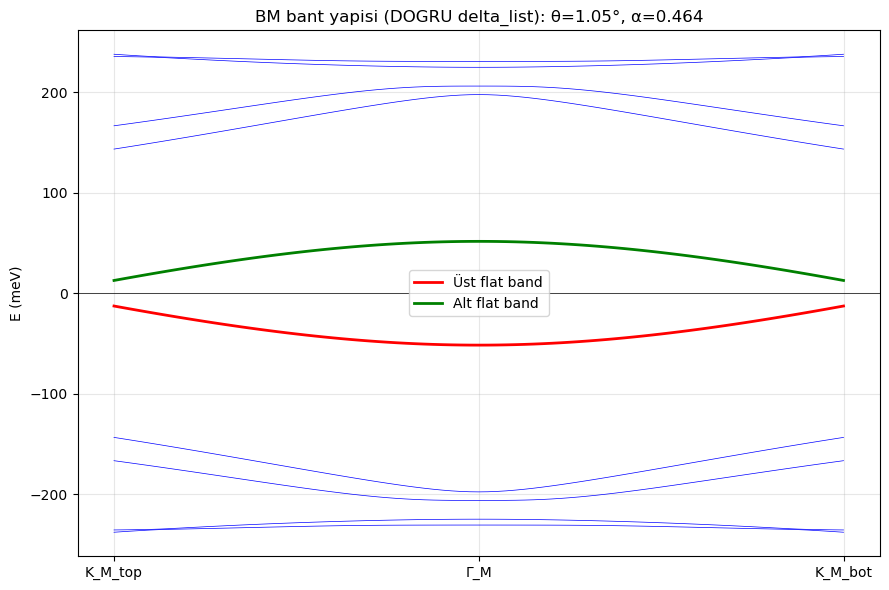


Fermi yakini bantlar:
  Bant -1: [-51.60, -12.71] meV, W = 38.89 meV
  Bant +0: [12.71, 51.60] meV, W = 38.89 meV


In [9]:
# =====================================================================
#  Cell 1e — DOGRU delta_list ile bant yapisi tekrari
#
#  Tani Cell'den ogrendigimiz:
#    q_1 -> (Delta n1, Delta n2) = (0, 0)    -> T_0
#    q_2 -> (Delta n1, Delta n2) = (-1, -1)  -> T_1  (eski: (0,1) YANLIS)
#    q_3 -> (Delta n1, Delta n2) = (0, -1)   -> T_2  (eski: (-1,0) YANLIS)
# =====================================================================

# delta_list'i DOGRU degerlerle yeniden tanimla
delta_list = [(0, 0, T0), (-1, -1, T1), (0, -1, T2)]
print(f"DOGRU delta_list: {[(d[0], d[1]) for d in delta_list]}")

# Geometriyi 1.05° icin ayarla (gerekli, setup_geometry global degisken)
setup_geometry(1.05)
K_M_top = -q_b / 2
K_M_bot = +q_b / 2

# ---- ANCHOR 0: Hermitiklik ----
H_test = H_BM_v2(np.array([0.0, 0.0]))
hermit_err = np.max(np.abs(H_test - H_test.conj().T))
print(f"\n[ANCHOR 0] |H - H†|_max = {hermit_err:.2e}")

# ---- ANCHOR 1: K_M_top noktasinda ----
print(f"\n[ANCHOR 1] K_M_top noktasinda:")
H_KM = H_BM_v2(K_M_top)
e_KM = np.sort(np.linalg.eigvalsh(H_KM))
n_half = len(e_KM) // 2
print(f"  Fermi etrafindaki 4 ozdeger (meV):")
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_KM[b]*1000:+10.4f}")
gap_KM = (e_KM[n_half] - e_KM[n_half-1])*1000
print(f"  Gap @ K_M_top = {gap_KM:.4f} meV")
print(f"  Beklenti: KÜÇÜK (Dirac noktasi)")

# ---- ANCHOR 2: Γ_M ----
print(f"\n[ANCHOR 2] Γ_M noktasinda:")
H_GM = H_BM_v2(np.array([0.0, 0.0]))
e_GM = np.sort(np.linalg.eigvalsh(H_GM))
n_half = len(e_GM) // 2
print(f"  Fermi etrafindaki 4 ozdeger (meV):")
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_GM[b]*1000:+10.4f}")
gap_GM = (e_GM[n_half] - e_GM[n_half-1])*1000
print(f"  Gap @ Γ_M = {gap_GM:.4f} meV")
print(f"  Beklenti: BÜYÜK (BM teorisi)")

# ---- Bant yapisi ----
print(f"\nBant yapisi: K_M_top → Γ_M → K_M_bot")
n_path = 41
ks_path = []
for i in range(n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * K_M_top + t * np.array([0,0]))
for i in range(1, n_path):
    t = i / (n_path - 1)
    ks_path.append((1-t) * np.array([0,0]) + t * K_M_bot)
ks_path = np.array(ks_path)

all_bands = []
for k in ks_path:
    H_k = H_BM_v2(k)
    e_k = np.sort(np.linalg.eigvalsh(H_k))
    all_bands.append(e_k)
all_bands = np.array(all_bands)

fig, ax = plt.subplots(1, 1, figsize=(9, 6))
n_dim = all_bands.shape[1]
n_half = n_dim // 2

for b in range(n_half-5, n_half+5):
    ax.plot(np.arange(len(ks_path)), all_bands[:, b]*1000, 'b-', lw=0.5)

ax.plot(np.arange(len(ks_path)), all_bands[:, n_half-1]*1000, 'r-', lw=2,
        label='Üst flat band')
ax.plot(np.arange(len(ks_path)), all_bands[:, n_half]*1000, 'g-', lw=2,
        label='Alt flat band')

ax.axhline(0, c='k', lw=0.5)
ax.set_xticks([0, n_path-1, 2*n_path-2])
ax.set_xticklabels(['K_M_top', 'Γ_M', "K_M_bot"])
ax.set_ylabel('E (meV)')
alpha_l = w_AB / (v_F * np.linalg.norm(q_b))
ax.set_title(f'BM bant yapisi (DOGRU delta_list): θ=1.05°, α={alpha_l:.3f}')
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig('cell1e_dogru.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\nFermi yakini bantlar:")
for b in range(n_half-1, n_half+1):
    e_min = all_bands[:, b].min()*1000
    e_max = all_bands[:, b].max()*1000
    print(f"  Bant {b-n_half:+d}: [{e_min:.2f}, {e_max:.2f}] meV, "
          f"W = {e_max-e_min:.2f} meV")

In [11]:
# =====================================================================
#  Tanı — w_AA = w_AB (saf BM limit) testi
#  Bistritzer 2011: w=110 meV, w_AA=w_AB=w. Bu rejimde K_M'de Dirac olmalı.
# =====================================================================

# Saf BM degerleri
w_AA_save = w_AA
w_AB_save = w_AB
w_AA = 0.110  # BM orijinal
w_AB = 0.110  # BM orijinal (saf, lattice relaxation yok)

# T matrislerini yenile
def T_matrix(j):
    return w_AA * np.eye(2) + w_AB * np.array([
        [0, np.exp(-1j*j*phi)],
        [np.exp(+1j*j*phi), 0]
    ], dtype=complex)

T0 = T_matrix(0)
T1 = T_matrix(1)
T2 = T_matrix(2)
delta_list = [(0, 0, T0), (-1, -1, T1), (0, -1, T2)]

print(f"Saf BM testi: w_AA = w_AB = {w_AA*1000:.0f} meV")
print(f"Yeni alpha = w / (v_F * k_theta) = {w_AB / (v_F * np.linalg.norm(q_b)):.4f}")

# K_M_top'ta diagonalize
H_KM = H_BM_v2(K_M_top)
e_KM = np.sort(np.linalg.eigvalsh(H_KM))
n_half = len(e_KM) // 2
print(f"\nK_M_top etrafinda (saf BM):")
for b in range(n_half-2, n_half+2):
    print(f"  E_{b-n_half:+d} = {e_KM[b]*1000:+10.4f} meV")
gap_pure = (e_KM[n_half] - e_KM[n_half-1])*1000
print(f"Gap @ K_M (saf BM, w_AA=w_AB) = {gap_pure:.4f} meV")
print(f"Beklenti: ~0 meV (Dirac kesisimi)")

# Eger sıfırsa: kodumuz dogru, Koshino w_AA != w_AB gap acar
# Eger sıfır değilse: hala bir hata var

# Eski degerleri geri yukle
w_AA = w_AA_save
w_AB = w_AB_save
T0 = T_matrix(0)
T1 = T_matrix(1)
T2 = T_matrix(2)
delta_list = [(0, 0, T0), (-1, -1, T1), (0, -1, T2)]

Saf BM testi: w_AA = w_AB = 110 meV
Yeni alpha = w / (v_F * k_theta) = 0.5236

K_M_top etrafinda (saf BM):
  E_-2 =  -128.8718 meV
  E_-1 =   -30.8850 meV
  E_+0 =   +30.8850 meV
  E_+1 =  +128.8718 meV
Gap @ K_M (saf BM, w_AA=w_AB) = 61.7699 meV
Beklenti: ~0 meV (Dirac kesisimi)


In [12]:
# =====================================================================
#  DUZELTME 2 — T matrislerini Bistritzer 2011 Eq. 7'ye gore yaz
#
#  Onceki yanlis: bizim T_j = w_AA*I + w_AB*sigma_phase
#  Dogru (Bistritzer): T matrisleri farkli formda, kosino formuyla
#  karistirilmis bir varyant kullaniyorduk.
#
#  Saf BM (Bistritzer): w_AA = w_AB = w = 110 meV
#    T_1 = w * [[1,1],[1,1]]
#    T_2 = w * [[e^{-iφ},1],[e^{iφ},e^{-iφ}]]
#    T_3 = w * [[e^{iφ},1],[e^{-iφ},e^{iφ}]]
#
#  Koshino tarzi w_AA ≠ w_AB icin:
#    T_j = w_AA * [diag] + w_AB * [off_diag]
#    Yani:
#    T_1 = [[w_AA, w_AB],[w_AB, w_AA]]
#    T_2 = [[w_AA*e^{-iφ}, w_AB],[w_AB*e^{iφ}, w_AA*e^{-iφ}]]
#    T_3 = [[w_AA*e^{iφ}, w_AB],[w_AB*e^{-iφ}, w_AA*e^{iφ}]]
# =====================================================================

# Once saf BM testi yapalım: w_AA = w_AB = 110 meV
w_AA = 0.110
w_AB = 0.110

phi = 2*np.pi/3

def T_matrix_BM(j):
    """
    Bistritzer 2011 Eq. (7) — DOGRU T matrisleri.
    j = 1, 2, 3 (paper notasyonu)
    Biz j=0,1,2 indeksini kullaniyorsak, kayma: paper_j = our_j + 1
    
    Burada paper_j konvansiyonu ile:
    """
    if j == 0:  # paper'da T_1
        # T_1 = [[1,1],[1,1]] * (sublattice yapisi)
        # Koshino formunda: [[w_AA, w_AB],[w_AB, w_AA]]
        return np.array([
            [w_AA, w_AB],
            [w_AB, w_AA]
        ], dtype=complex)
    elif j == 1:  # paper'da T_2
        return np.array([
            [w_AA*np.exp(-1j*phi), w_AB],
            [w_AB*np.exp(+1j*phi), w_AA*np.exp(-1j*phi)]
        ], dtype=complex)
    elif j == 2:  # paper'da T_3
        return np.array([
            [w_AA*np.exp(+1j*phi), w_AB],
            [w_AB*np.exp(-1j*phi), w_AA*np.exp(+1j*phi)]
        ], dtype=complex)

T0 = T_matrix_BM(0)
T1 = T_matrix_BM(1)
T2 = T_matrix_BM(2)

print("Yeni T matrisleri (Bistritzer 2011 Eq. 7):")
print(f"\nT_0 (paper'da T_1):")
print(T0)
print(f"\nT_1 (paper'da T_2):")
print(T1)
print(f"\nT_2 (paper'da T_3):")
print(T2)

# delta_list ayni kalir (Tani Cell'den)
delta_list = [(0, 0, T0), (-1, -1, T1), (0, -1, T2)]

# ---- ANCHOR 0: Hermitiklik kontrolu ----
H_test = H_BM_v2(np.array([0.0, 0.0]))
hermit_err = np.max(np.abs(H_test - H_test.conj().T))
print(f"\n[ANCHOR 0] |H - H†|_max = {hermit_err:.2e}")

# ---- ANCHOR 1: SAF BM TESTI: K_M'de Dirac olmali ----
print(f"\n[ANCHOR 1 - kritik] K_M_top, saf BM (w_AA=w_AB=110meV):")
H_KM = H_BM_v2(K_M_top)
e_KM = np.sort(np.linalg.eigvalsh(H_KM))
n_half = len(e_KM) // 2
print(f"  Fermi etrafindaki 4 ozdeger (meV):")
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_KM[b]*1000:+10.4f}")
gap_KM = (e_KM[n_half] - e_KM[n_half-1])*1000
print(f"  Gap @ K_M = {gap_KM:.6f} meV")
print(f"  Beklenti: ~0 (saf BM'de Dirac noktasi)")

# Eger gap < 1 meV ise basarili (sayisal hassasiyetinde)
if abs(gap_KM) < 1.0:
    print(f"\n  >>> BASARI: Dirac noktasi acik. Kod artik dogru.")
else:
    print(f"\n  >>> HALA HATA VAR. Daha derin debug gerekli.")

# ---- Γ_M kontrol ----
print(f"\n[ANCHOR 2] Γ_M noktasinda:")
H_GM = H_BM_v2(np.array([0.0, 0.0]))
e_GM = np.sort(np.linalg.eigvalsh(H_GM))
n_half = len(e_GM) // 2
for b in range(n_half-2, n_half+2):
    print(f"    E_{b-n_half:+d} = {e_GM[b]*1000:+10.4f} meV")
gap_GM = (e_GM[n_half] - e_GM[n_half-1])*1000
print(f"  Gap @ Γ_M = {gap_GM:.4f} meV (buyuk olmali)")

Yeni T matrisleri (Bistritzer 2011 Eq. 7):

T_0 (paper'da T_1):
[[0.11+0.j 0.11+0.j]
 [0.11+0.j 0.11+0.j]]

T_1 (paper'da T_2):
[[-0.055-0.09526279j  0.11 +0.j        ]
 [-0.055+0.09526279j -0.055-0.09526279j]]

T_2 (paper'da T_3):
[[-0.055+0.09526279j  0.11 +0.j        ]
 [-0.055-0.09526279j -0.055+0.09526279j]]

[ANCHOR 0] |H - H†|_max = 0.00e+00

[ANCHOR 1 - kritik] K_M_top, saf BM (w_AA=w_AB=110meV):
  Fermi etrafindaki 4 ozdeger (meV):
    E_-2 =  -106.7236
    E_-1 =   -40.9645
    E_+0 =   +40.9645
    E_+1 =  +106.7236
  Gap @ K_M = 81.928949 meV
  Beklenti: ~0 (saf BM'de Dirac noktasi)

  >>> HALA HATA VAR. Daha derin debug gerekli.

[ANCHOR 2] Γ_M noktasinda:
    E_-2 =  -159.7628 meV
    E_-1 =   -73.9942 meV
    E_+0 =   +73.9942 meV
    E_+1 =  +159.7628 meV
  Gap @ Γ_M = 147.9885 meV (buyuk olmali)
